# 03 - Feature engineering 

>> in this example for nginx logs

This notebook parses the three raw Nginx log sources, builds the 5-minute (modifiable at any window size (currently WINDOW_SIZE = "5min") in `src/fink_api_anomaly_detection/features/nginx_logs/common.py`) temporal feature table, and checks the feature definitions and experiment subsets. It follows the data-loading pattern from notebook 02. The three sources are aggregated independently and only joined after aggregation.

## Setup and load the parsed DataFrames

The parsing functions return `access_df`, `geo_df`, and `errors_df`, as in notebook 02. 

In [1]:
import sys
from pathlib import Path

import pandas as pd
from IPython.display import display

project_root = Path.cwd().parent 
sys.path.append(str(project_root))

from src.fink_api_anomaly_detection.data.raw_logs import ls_log_files
from src.fink_api_anomaly_detection.preprocess.nginx_logs.access_logs import build_access_dataframe
from src.fink_api_anomaly_detection.preprocess.nginx_logs.error_logs import build_error_dataframe
from src.fink_api_anomaly_detection.preprocess.nginx_logs.geo_logs import build_geo_dataframe
from src.fink_api_anomaly_detection.features.nginx_logs import (
    build_feature_subsets,
    build_temporal_features,
)

DATA_DIR = project_root / "data" / "nginx_history_logs"
print(f"Dataset directory: {DATA_DIR.relative_to(project_root)}")

Dataset directory: data/nginx_history_logs


### Smoke-test the feature pipeline

here we have a small deterministic example. It checks the 5-minute flooring, retention of an empty interval, the endpoint split, and the experiment subset sizes before processing the full dataset.

In [2]:
sample_access_df = pd.DataFrame(
    [
        {
            "timestamp": "2026-10-03T10:01:00Z",
            "method": "GET",
            "status_code": 404,
            "client_ip": "192.0.2.1",
            "bytes_sent": 128,
            "endpoint": "/api/v1/objects",
        },
        {
            "timestamp": "2026-10-03T10:11:00Z",
            "method": "POST",
            "status_code": 500,
            "client_ip": "192.0.2.2",
            "bytes_sent": 256,
            "endpoint": None,
        },
    ]
)

sample_geo_df = pd.DataFrame([{"timestamp": "2026-10-03T10:01:00Z", "country": "France"}])

sample_errors_df = pd.DataFrame(
    [
        {
            "timestamp": "2026-10-03T10:11:00Z",
            "error_level": "crit",
            "error_message": "upstream timed out",
            "error_description": "Connection timed out",
        }
    ]
)

sample_features_df = build_temporal_features(sample_access_df, sample_geo_df, sample_errors_df)

assert sample_features_df.shape == (3, 23)
assert sample_features_df["request_count"].tolist() == [1, 0, 1]
assert sample_features_df["endpoint_api_count"].tolist() == [1, 0, 0]
assert sample_features_df["endpoint_unrecognized_count"].tolist() == [0, 0, 1]
assert sample_features_df["nginx_timeout_count"].tolist() == [0, 0, 1]
assert sample_features_df["request_count_delta"].tolist() == [0, -1, 1]
assert [subset.shape[1] for subset in build_feature_subsets(sample_features_df).values()] == [9, 14, 16, 19, 22]
display(sample_features_df)
print("Synthetic feature pipeline: all checks passed")

,timestamp,request_count,get_count,post_count,http_4xx_count,http_5xx_count,http_4xx_rate,http_5xx_rate,unique_client_count,bytes_sent_sum,...,nginx_connection_reset_count,nginx_broken_pipe_count,unique_country_count,top_country_share,endpoint_api_count,endpoint_unrecognized_count,unique_endpoint_count,request_count_delta,http_5xx_rate_delta,nginx_error_count_delta
0,2026-10-03 10:00:00+00:00,1,1,0,1,0,1.0,0.0,1,128,...,0,0,1,1.0,1,0,1,0.0,0.0,0.0
1,2026-10-03 10:05:00+00:00,0,0,0,0,0,0.0,0.0,0,0,...,0,0,0,0.0,0,0,0,-1.0,0.0,0.0
2,2026-10-03 10:10:00+00:00,1,0,1,0,1,0.0,1.0,1,256,...,0,0,0,0.0,0,1,0,1.0,1.0,1.0


Synthetic feature pipeline: all checks passed


Listing of available log files per category:

In [3]:
access_files = ls_log_files(DATA_DIR, "access-logs")
geo_files = ls_log_files(DATA_DIR, "geo-logs")
error_files = ls_log_files(DATA_DIR, "error-logs")

Parsing the compressed files can take a little while for the full dataset : 

In [4]:
access_df = build_access_dataframe(access_files)
geo_df = build_geo_dataframe(geo_files)
errors_df = build_error_dataframe(error_files)

In [5]:
print(f"access_df.shape: {access_df.shape}")
print(f"geo_df.shape: {geo_df.shape}")
print(f"errors_df.shape: {errors_df.shape}")

access_df.shape: (1005103, 16)
geo_df.shape: (1005103, 6)
errors_df.shape: (833, 17)


## Build and inspect the 5-minute dataset

Each source is aggregated using its own timestamp and fields. The final merge happens on the floored UTC window timestamp; no row-by-row join of raw logs is performed.

The current data contains 4,033 five-minute grid rows. The final window, starting at 2026-10-17 00:00 UTC, is partial and contains six requests; exclude it from evaluation, leaving 4,032 complete windows.

In [6]:
features_df = build_temporal_features(access_df, geo_df, errors_df)

print(f"Temporal dataset shape: {features_df.shape}")
print(f"Number of time windows: {len(features_df):}")
print(f"Time span: {features_df['timestamp'].min()} to {features_df['timestamp'].max()}")
display(features_df.head())
display(features_df.tail())

Temporal dataset shape: (4033, 23)
Number of time windows: 4033
Time span: 2026-10-03 00:00:00+00:00 to 2026-10-17 00:00:00+00:00


,timestamp,request_count,get_count,post_count,http_4xx_count,http_5xx_count,http_4xx_rate,http_5xx_rate,unique_client_count,bytes_sent_sum,...,nginx_connection_reset_count,nginx_broken_pipe_count,unique_country_count,top_country_share,endpoint_api_count,endpoint_unrecognized_count,unique_endpoint_count,request_count_delta,http_5xx_rate_delta,nginx_error_count_delta
0,2026-10-03 00:00:00+00:00,30,1,29,0,2,0.0,0.066667,6,1197413,...,0,0,3,0.600000,30,0,4,0.0,0.0,0.0
1,2026-10-03 00:05:00+00:00,36,0,36,0,0,0.0,0.0,4,3077416,...,0,0,3,0.472222,36,0,4,6.0,-0.066667,0.0
2,2026-10-03 00:10:00+00:00,353,1,352,0,0,0.0,0.0,9,83959825,...,0,0,4,0.929178,353,0,4,317.0,0.0,0.0
3,2026-10-03 00:15:00+00:00,363,1,362,0,0,0.0,0.0,9,100850864,...,0,0,4,0.851240,363,0,5,10.0,0.0,0.0
4,2026-10-03 00:20:00+00:00,327,2,325,1,4,0.003058,0.012232,8,72522424,...,1,1,3,0.935583,326,1,5,-36.0,0.012232,2.0


,timestamp,request_count,get_count,post_count,http_4xx_count,http_5xx_count,http_4xx_rate,http_5xx_rate,unique_client_count,bytes_sent_sum,...,nginx_connection_reset_count,nginx_broken_pipe_count,unique_country_count,top_country_share,endpoint_api_count,endpoint_unrecognized_count,unique_endpoint_count,request_count_delta,http_5xx_rate_delta,nginx_error_count_delta
4028,2026-10-16 23:40:00+00:00,44,2,42,0,0,0.0,0.0,10,608838,...,0,0,3,0.772727,44,0,6,3.0,0.0,0.0
4029,2026-10-16 23:45:00+00:00,79,4,75,0,0,0.0,0.0,8,1021306,...,0,0,4,0.772152,76,3,9,35.0,0.0,0.0
4030,2026-10-16 23:50:00+00:00,71,4,67,0,2,0.0,0.028169,10,371111,...,1,0,3,0.563380,71,0,10,-8.0,0.028169,1.0
4031,2026-10-16 23:55:00+00:00,67,4,63,0,0,0.0,0.0,10,1450850,...,0,0,4,0.462687,67,0,7,-4.0,-0.028169,-1.0
4032,2026-10-17 00:00:00+00:00,6,0,6,0,0,0.0,0.0,1,42405,...,0,0,1,1.000000,6,0,1,-61.0,0.0,0.0


Check the output shape, ordering, regular frequency, and feature types : 

In [7]:
assert features_df.shape[1] == 23, f"Expected timestamp + 22 features; found {features_df.shape[1]} columns."
assert features_df.columns[0] == "timestamp"
assert features_df.columns.is_unique
assert str(features_df["timestamp"].dt.tz) == "UTC"
assert features_df["timestamp"].is_monotonic_increasing
assert not features_df["timestamp"].duplicated().any()
assert features_df["timestamp"].diff().dropna().dt.total_seconds().eq(300).all()

numeric_features = features_df.columns.drop("timestamp")
assert features_df[numeric_features].select_dtypes(include="number").shape[1] == 22
assert features_df[numeric_features].notna().all().all()
print("Output checks passed: 22 numeric features on a complete UTC 5-minute grid")

Output checks passed: 22 numeric features on a complete UTC 5-minute grid


### Inspect traffic and reliability

Rates are proportions between 0 and 1. Empty windows have zero counts and zero rates; deltas compare each window to the immediately previous row.

,timestamp,request_count,get_count,post_count,http_4xx_count,http_5xx_count,http_4xx_rate,http_5xx_rate,unique_client_count,bytes_sent_sum,...,nginx_connection_reset_count,nginx_broken_pipe_count,unique_country_count,top_country_share,endpoint_api_count,endpoint_unrecognized_count,unique_endpoint_count,request_count_delta,http_5xx_rate_delta,nginx_error_count_delta
count,4033,4033.000000,4033.000000,4033.000000,4033.000000,4033.000000,4033.0,4033.0,4033.000000,4.033000e+03,...,4033.000000,4033.000000,4033.000000,4033.000000,4033.000000,4033.000000,4033.000000,4033.000000,4033.0,4033.000000
mean,2026-10-10 00:00:00+00:00,249.219688,26.472601,222.547979,10.336226,3.522440,0.013439,0.013572,11.167617,3.460928e+07,...,0.105877,0.049343,5.025539,0.665538,234.640218,14.579469,28.744855,-0.005951,-0.000017,0.000000
min,2026-10-03 00:00:00+00:00,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.000000e+00,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-3621.000000,-1.0,-23.000000
25%,2026-10-06 12:00:00+00:00,69.000000,2.000000,57.000000,0.000000,0.000000,0.0,0.0,9.000000,1.250648e+06,...,0.000000,0.000000,4.000000,0.500000,67.000000,0.000000,7.000000,-36.000000,-0.001653,0.000000
50%,2026-10-10 00:00:00+00:00,132.000000,5.000000,117.000000,0.000000,0.000000,0.0,0.0,10.000000,3.368959e+06,...,0.000000,0.000000,5.000000,0.666667,127.000000,0.000000,10.000000,1.000000,0.0,0.000000
75%,2026-10-13 12:00:00+00:00,358.000000,20.000000,347.000000,0.000000,1.000000,0.0,0.008065,13.000000,6.067982e+07,...,0.000000,0.000000,6.000000,0.846561,353.000000,1.000000,24.000000,38.000000,0.001464,0.000000
max,2026-10-17 00:00:00+00:00,10273.000000,9905.000000,4088.000000,8399.000000,323.000000,1.0,1.0,72.000000,2.414253e+08,...,9.000000,2.000000,11.000000,1.000000,4111.000000,10151.000000,8853.000000,5563.000000,1.0,23.000000
std,NaN,390.750654,277.957508,272.249944,221.854538,17.541887,0.075867,0.05073,4.753306,5.286638e+07,...,0.383110,0.225584,1.271869,0.195620,277.674326,280.337247,253.020494,214.852364,0.058088,0.941756


Text(0, 0.5, 'proportion')

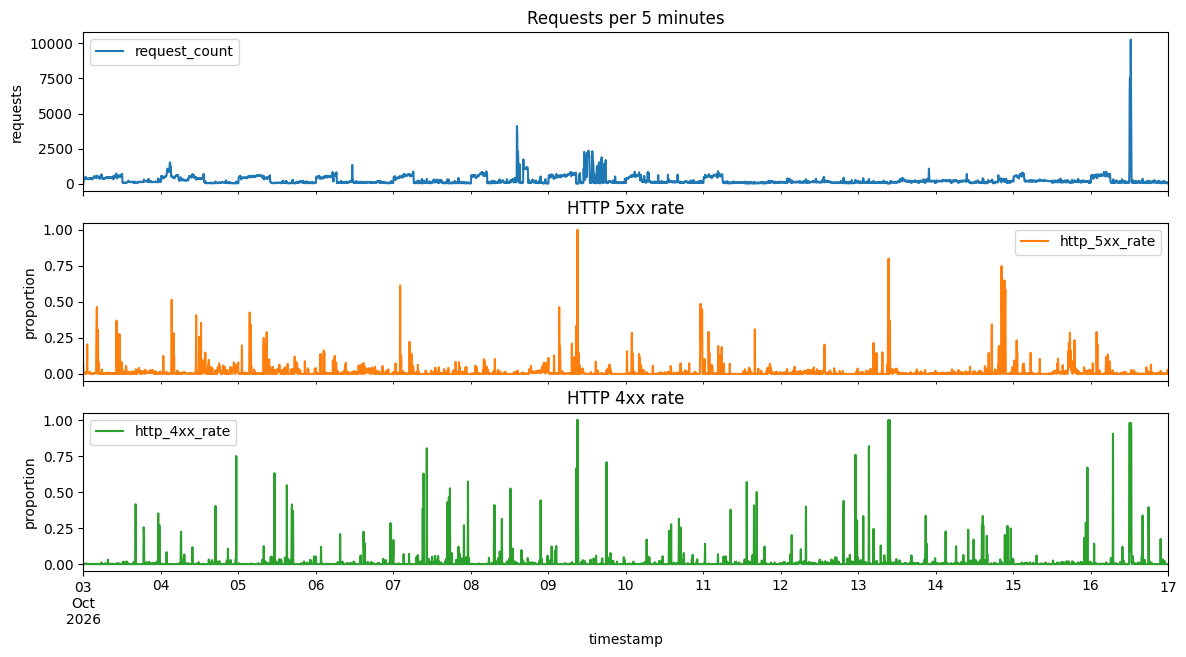

In [8]:
display(features_df.describe(include="all"))

ax = features_df.set_index("timestamp")[["request_count", "http_5xx_rate","http_4xx_rate"]].plot(
    subplots=True, figsize=(14, 7), title=["Requests per 5 minutes", "HTTP 5xx rate", "HTTP 4xx rate"]
)
ax[0].set_ylabel("requests")
ax[1].set_ylabel("proportion")
ax[2].set_ylabel("proportion")

Across the 14 complete UTC days, the correlation between daily 4xx and 5xx counts is approximately **-0.06**, replacing the earlier estimate. This short observation period does not show a meaningful linear relationship.

## Validate feature definitions

Endpoint counts should partition access requests. The geography share uses only rows with an available country, and Nginx error categories are counted independently of HTTP status codes.

In [9]:
assert (features_df["endpoint_api_count"] + features_df["endpoint_unrecognized_count"] == features_df["request_count"]).all()
assert (features_df["http_4xx_rate"].between(0, 1)).all()
assert (features_df["http_5xx_rate"].between(0, 1)).all()
assert (features_df["top_country_share"].between(0, 1)).all()

delta_checks = {
    "request_count_delta": features_df["request_count"].diff().fillna(0),
    "http_5xx_rate_delta": features_df["http_5xx_rate"].diff().fillna(0),
    "nginx_error_count_delta": features_df["nginx_error_count"].diff().fillna(0),
}
for feature, expected in delta_checks.items():
    pd.testing.assert_series_equal(
        features_df[feature], expected, check_names=False, check_dtype=False
    )
print("Feature definition checks passed")

Feature definition checks passed


## Prepare the experiment feature (df) subsets

The returned DataFrames contain only model inputs; timestamps remain available in `features_df` for temporal ordering and evaluation.

In [10]:
feature_sets = build_feature_subsets(features_df)
subset_summary = pd.DataFrame(
    {
        "feature_count": {name: subset.shape[1] for name, subset in feature_sets.items()},
        "row_count": {name: len(subset) for name, subset in feature_sets.items()},
    }
)
display(subset_summary)

df_b = feature_sets["baseline"]
df_bn = feature_sets["baseline_nginx"]
df_bng = feature_sets["baseline_nginx_geography"]
df_bnge = feature_sets["baseline_nginx_geography_endpoints"]
df_all = feature_sets["all"]

assert [subset.shape[1] for subset in feature_sets.values()] == [9, 14, 16, 19, 22]
assert all(subset.index.equals(features_df.index) for subset in feature_sets.values())
print("Feature subsets are ready for experiments")

,feature_count,row_count
baseline,9,4033
baseline_nginx,14,4033
baseline_nginx_geography,16,4033
baseline_nginx_geography_endpoints,19,4033
all,22,4033


Feature subsets are ready for experiments


## Summary

`features_df` is the complete timestamped 23 features dataset. `feature_sets` contains the five model input (Dataframes) configurations (`baseline`, `baseline_nginx`, `baseline_nginx_geography`, `baseline_nginx_geography_endpoints`, and `all`). we can also keep timestamps aligned with each feature subset when we want to do temporal splitting or scoring time series data.